In [20]:
from sklearn.preprocessing import (StandardScaler,RobustScaler,MinMaxScaler)
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [21]:
df = pd.read_csv("/home/havin-benoy/Desktop/Pyspiders/ml/Datasets/loan_data.csv")
df

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


In [22]:
x = df.drop(columns="loan_status")
y = df["loan_status"]

In [23]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)

In [24]:
numerical_columns = x.select_dtypes(include = 'number')        # include = ('int','float')
numerical_columns

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586
...,...,...,...,...,...,...,...,...
44995,27.0,47971.0,6,15000.0,15.66,0.31,3.0,645
44996,37.0,65800.0,17,9000.0,14.07,0.14,11.0,621
44997,33.0,56942.0,7,2771.0,10.02,0.05,10.0,668
44998,29.0,33164.0,4,12000.0,13.23,0.36,6.0,604


{'whiskers': [<matplotlib.lines.Line2D at 0x7392b069b230>,
 'caps': [<matplotlib.lines.Line2D at 0x7392b069b710>,
 'boxes': [<matplotlib.lines.Line2D at 0x7392b07bdb20>,
 'medians': [<matplotlib.lines.Line2D at 0x7392b069bc50>,
 'fliers': [<matplotlib.lines.Line2D at 0x7392b069bef0>,
 'means': []}

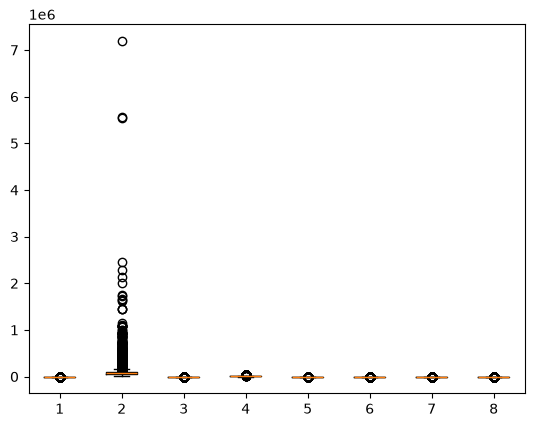

In [25]:
# To see the outlier status of each of the columns

plt.boxplot(numerical_columns)

- this plot is misleading
- so we should analyse ouliers of each of the numerical column by boxplot seperately to know if it is having high outliers , medium number of outliers or no outliers.
- So that we can choose  the right type of scaling technique (RobustScaler, StandardScaler or MinMaxScaler)
- Robust Scaler is used if there is High amount of outliers in the Numerical column.
- Standard Scaler is used if there is Medium amount of outliers (only less than 5% of data are outliers) in the Numerical column.
- MinMax Scaler is used if there is No outliers in the Numerical column.

## How to analyze the boxplot for the outliers.
- in boxplot there is a box
- outside the box there is two horizontal lines .One is on top side of the box and one is in the bottom side.
- the circle points that are outside these horizontal lines are the outliers
- each circle point denotes a record in the numerical column that is an outlier in comparison to the distribution of the other datas
- from the y axis we can know that , what range of values of the numerical column is outliers
- for example in the below boxplot (plt.boxplot(df['person_age'])), we can see that the values from 40 to 140 are outliers.
- so we can count the values between 40 and 140 in the column of df['person_age'] to see how many outliers are there in the column.
- with that information we can understand what percentage of the values are outliers
- if there is more than 5% of outliers in the numerical column , then we will choose Robust Scaler for scaling that column
- if outliers are less than 5 % then we can choose Standard Scaler for scaling that column
- if there is no outliers atall (no circle points outside the box) then we can choose MInMax Scaler for the scaling of that numerical column.


{'whiskers': [<matplotlib.lines.Line2D at 0x7392ae543170>,
 'caps': [<matplotlib.lines.Line2D at 0x7392ae543620>,
 'boxes': [<matplotlib.lines.Line2D at 0x7392ae542f00>],
 'medians': [<matplotlib.lines.Line2D at 0x7392ae543b60>],
 'fliers': [<matplotlib.lines.Line2D at 0x7392ae543e00>],
 'means': []}

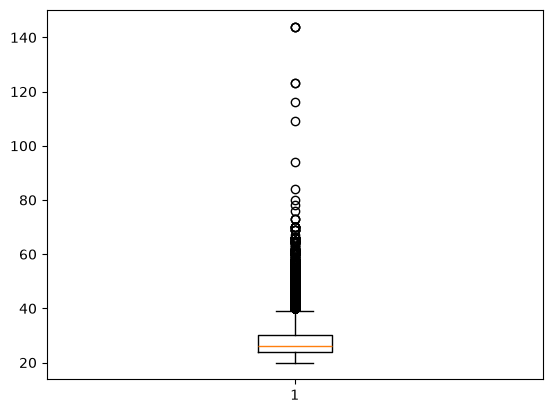

In [26]:
plt.boxplot(df['person_age'])

- high outlier so robust scaler

{'whiskers': [<matplotlib.lines.Line2D at 0x7392ae5a0ec0>,
 'caps': [<matplotlib.lines.Line2D at 0x7392ae5a3740>,
 'boxes': [<matplotlib.lines.Line2D at 0x7392ae5a3230>],
 'medians': [<matplotlib.lines.Line2D at 0x7392ae5a3c50>],
 'fliers': [<matplotlib.lines.Line2D at 0x7392ae5a3ef0>],
 'means': []}

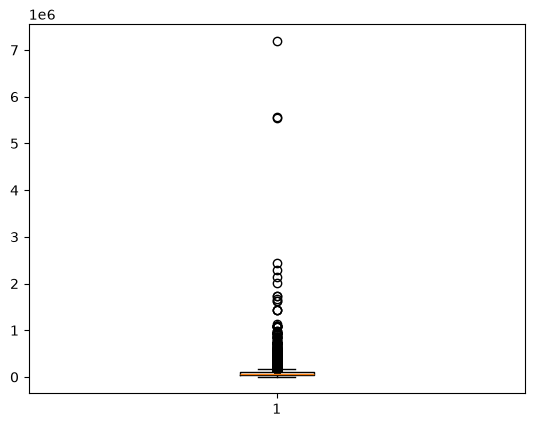

In [27]:
plt.boxplot(df['person_income'])

- High outliers so Robust scaler

{'whiskers': [<matplotlib.lines.Line2D at 0x7392ae403710>,
 'caps': [<matplotlib.lines.Line2D at 0x7392ae403bf0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7392ae403440>],
 'medians': [<matplotlib.lines.Line2D at 0x7392ae430170>],
 'fliers': [<matplotlib.lines.Line2D at 0x7392ae430410>],
 'means': []}

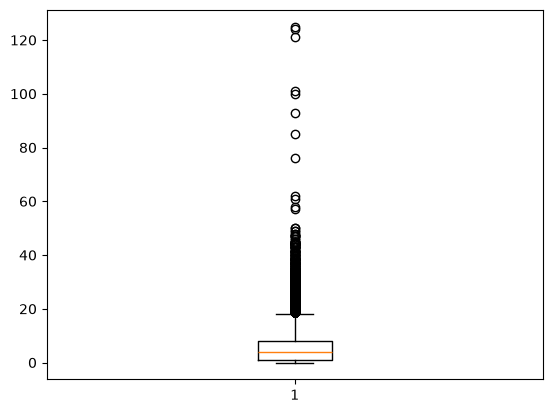

In [28]:
plt.boxplot(df['person_emp_exp'])

- High outliers so Robust scaler

{'whiskers': [<matplotlib.lines.Line2D at 0x7392ae463a40>,
 'caps': [<matplotlib.lines.Line2D at 0x7392ae463f80>,
 'boxes': [<matplotlib.lines.Line2D at 0x7392ae4637d0>],
 'medians': [<matplotlib.lines.Line2D at 0x7392ae4884d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7392ae488770>],
 'means': []}

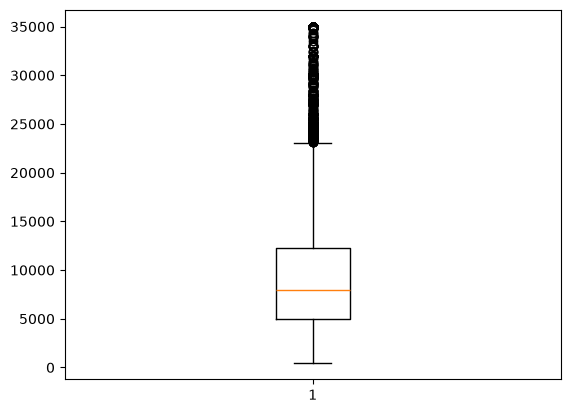

In [29]:
plt.boxplot(df['loan_amnt'])

- High outliers so Robust scaler

{'whiskers': [<matplotlib.lines.Line2D at 0x7392ae4dcdd0>,
 'caps': [<matplotlib.lines.Line2D at 0x7392ae4dd310>,
 'boxes': [<matplotlib.lines.Line2D at 0x7392ae4dcb90>],
 'medians': [<matplotlib.lines.Line2D at 0x7392ae4dd7f0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7392ae4dda00>],
 'means': []}

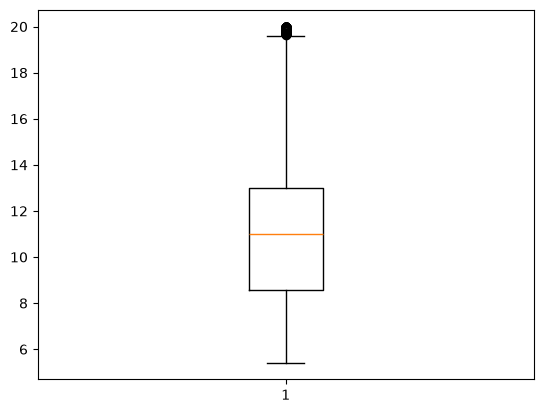

In [30]:
plt.boxplot(df['loan_int_rate'])

- less outlier so could be standard scaler (needs to verify the outlier percentage)

{'whiskers': [<matplotlib.lines.Line2D at 0x7392ae3393a0>,
 'caps': [<matplotlib.lines.Line2D at 0x7392ae339850>,
 'boxes': [<matplotlib.lines.Line2D at 0x7392ae339100>],
 'medians': [<matplotlib.lines.Line2D at 0x7392ae339c10>],
 'fliers': [<matplotlib.lines.Line2D at 0x7392ae339eb0>],
 'means': []}

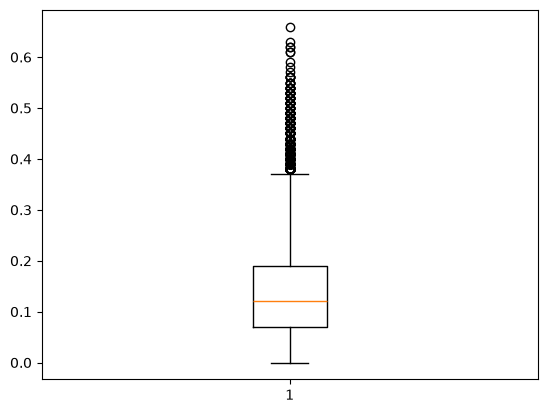

In [31]:
plt.boxplot(df['loan_percent_income'])

- less outlier so could be standard scaler (needs to verify the outlier percentage)

{'whiskers': [<matplotlib.lines.Line2D at 0x7392ae391370>,
 'caps': [<matplotlib.lines.Line2D at 0x7392ae3918b0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7392ae3911c0>],
 'medians': [<matplotlib.lines.Line2D at 0x7392ae391df0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7392ae391f10>],
 'means': []}

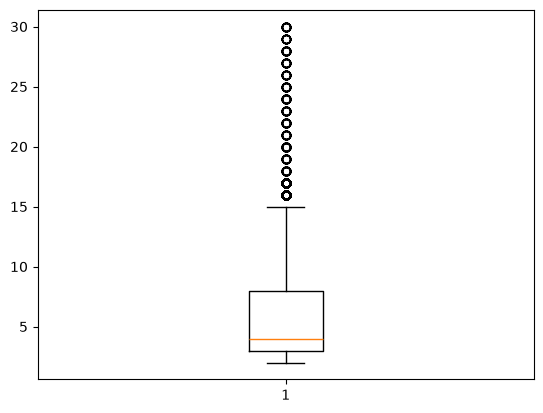

In [32]:
plt.boxplot(df['cb_person_cred_hist_length'])

- less outlier so could be standard scaler (needs to verify the outlier percentage)

{'whiskers': [<matplotlib.lines.Line2D at 0x7392ae3d7f50>,
 'caps': [<matplotlib.lines.Line2D at 0x7392ae2004d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7392ae3d7ce0>],
 'medians': [<matplotlib.lines.Line2D at 0x7392ae200a10>],
 'fliers': [<matplotlib.lines.Line2D at 0x7392ae200cb0>],
 'means': []}

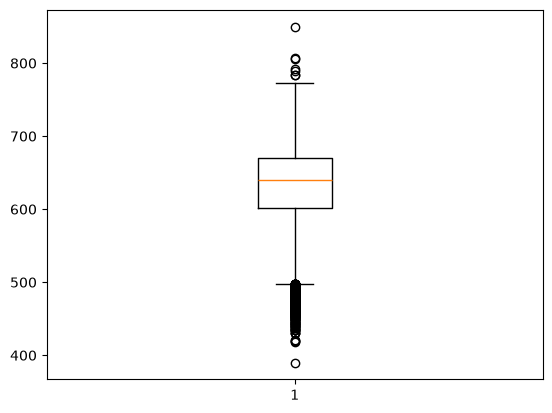

In [33]:
plt.boxplot(df['credit_score'])

- High outliers so Robust scaler